# 04 - Model comparison per target

**Goal:** find out whether any model beats the simple logistic baselines of notebook 03 on each target, and settle the questions that had to wait for this comparison.

**Inputs:** `data/raw/*.csv` through `miopia.data.load_raw()`, `clean_features`, and the modules `miopia.validation` and `miopia.models`.

**Outputs:** the model chosen for each target (fitted and used for the test labels in notebook 05), `src/miopia/models.py`, and the figures `04_*.png`.

**Assumptions touched:** B1, B2, B3, B12, B13, B14, B15, B16 and B17, see `docs/assumptions.md`. `MM` is trained on the corrected labels (B2): the 8 students with `Combo = MM` have `MM = SI`. The other targets use their columns as provided. The test set is not used in this notebook.

## 1. Setup and data loading

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, TunedThresholdClassifierCV

from miopia.config import RANDOM_STATE, RESULTS
from miopia.data import load_raw
from miopia.features import clean_features, with_axial_corneal_ratio
from miopia.models import CANDIDATES, final_model, ordinal_model, tuned_model, with_tuned_threshold
from miopia.plotting import BLUE, CLASS_COLORS, CLASS_MARKERS, VERMILLION, save_fig, set_style
from miopia.validation import (
    N_REPEATS, SUMMARY_METRICS, correct_mm_labels, evaluate, logistic_baseline, make_strata, selection_test,
)

set_style()
pd.set_option("display.width", 160)
TARGETS = ["M", "MM", "Combo", "DCombo"]
SECOND_SEED = RANDOM_STATE + 1
X_train_raw, Y_provided, _ = load_raw()     # the test rows are not needed here
Y_train = correct_mm_labels(Y_provided)     # B2: the 8 inconsistent MM labels corrected
X_train = clean_features(X_train_raw)
strata = {t: make_strata(Y_train, t) for t in TARGETS}
print(f"train {X_train.shape}")

train (132, 32)


## 2. Which rules decide the winner?

These rules were written before any model in this notebook was run (B14), with two exceptions: route B, explained under *Test to pass*, and the repeated inner split used to tune the `MM` threshold (section 8).

- **Candidates.** Tuned logistic regression, an SVM with an RBF kernel, a random forest and XGBoost, all on the 32 features. Linear, kernel and two kinds of tree ensemble cover different shapes of relationship.
- **Nested cross-validation.** The outer loop is the 5-fold, 10-repeat scheme of notebook 03. Inside each outer training set, a grid search with 3 folds picks the hyperparameters by balanced accuracy. The outer validation rows are never seen by the search, so the outer scores are not inflated by trying many settings. The grids are small on purpose, since 132 students cannot support a large search.
- **Reference.** For each target, whichever logistic baseline of notebook 03 has the higher balanced accuracy.
- **Test to pass.** A candidate passes by either of two routes. Route A: balanced accuracy clearly better than the reference (B12), and macro-F1 not clearly worse; if macro-F1 is clearly worse, accuracy decides and must be clearly better (B13). Route B: balanced accuracy not clearly worse, and both macro-F1 and accuracy clearly better. Route B was added after seeing the first validation results, because route A alone rejected a model that was clearly worse on no metric and clearly better on two. It relaxes the requirement stated in notebook 03, which asked for clearly better balanced accuracy. The test set played no part in this, but a rule adjusted after seeing validation scores can make those scores somewhat optimistic.
- **Winner.** Among those that pass, the highest balanced accuracy, which must pass again on a second set of folds. If nothing passes, the reference stays. The second set of folds uses the same students, so it only guards against the luck of one split.

"Clearly" keeps the meaning given in notebook 03: a stability check across new splits of the same students, not evidence about new students. Section 11 measures how often this test passes for useless information, and it does so too often on some targets.

## 3. What is XGBoost, and why try it?

XGBoost was not covered in class, so here is what it does. It builds many small decision trees one after another. Each new tree is fitted to correct the errors of the trees before it, and its contribution is scaled down by the learning rate, so the model improves in small steps. A random forest, by contrast, grows its trees independently and averages them.

XGBoost is known for doing well on tabular data, and it can capture interactions between features without being told about them. The risk with 132 students is overfitting, so we limit it: shallow trees (depth 2 or 3), a small grid, and each tree sees only part of the students and of the features. We also weight the classes to match the other candidates. Trees do not need scaling, so only the median imputation is applied.

## 4. How do the candidates score?

**What and why:** every candidate runs through the nested scheme on every target, on the same outer folds as the two logistic baselines, so the comparisons are paired.

In [2]:
def run_all(seed=RANDOM_STATE):
    frames, predictions = {}, {}
    baselines = {"Logistic, axial length only": (logistic_baseline(), X_train[["axial_length"]]),
                 "Logistic, all 32 features": (logistic_baseline(), X_train)}
    models = {**baselines, **{name: (tuned_model(name), X_train) for name in CANDIDATES}}
    for target in TARGETS:
        for name, (model, data) in models.items():
            frame, pred = evaluate(model, data, Y_train[target], Y_train[target], strata[target], seed=seed)
            frames[target, name], predictions[target, name] = frame, pred
    return frames, predictions

frames, predictions = run_all()
scores = pd.DataFrame({key: frame[SUMMARY_METRICS].mean() for key, frame in frames.items()}).T
scores.insert(1, "balanced_accuracy_sd", [frame["balanced_accuracy"].std() for frame in frames.values()])
scores.index.names = ["target", "model"]
scores.round(2)

balanced_accuracy  balanced_accuracy_sd  macro_f1  accuracy   mcc
target model                                                                                         
M      Logistic, axial length only               0.77                  0.08      0.75      0.77  0.52
       Logistic, all 32 features                 0.77                  0.10      0.76      0.78  0.53
       Logistic, tuned                           0.76                  0.10      0.74      0.77  0.50
       SVM (RBF)                                 0.70                  0.10      0.69      0.73  0.41
       Random forest                             0.74                  0.08      0.73      0.76  0.48
       XGBoost                                   0.74                  0.08      0.73      0.76  0.49
MM     Logistic, axial length only               0.88                  0.08      0.80      0.88  0.64
       Logistic, all 32 features                 0.87                  0.10      0.83      0.91  0.68
       Logistic, tuned                           0.87                  0.09      0.81      0.89  0.65
       SVM (RBF)                                 0.86                  0.12      0.81      0.90  0.65
       Random forest                             0.89                  0.10      0.90      0.96  0.81
       XGBoost                                   0.90                  0.09      0.90      0.96  0.82
Combo  Logistic, axial length only               0.71                  0.07      0.66      0.65  0.45
       Logistic, all 32 features                 0.70                  0.10      0.67      0.67  0.47
       Logistic, tuned                           0.66                  0.11      0.62      0.62  0.40
       SVM (RBF)                                 0.67                  0.13      0.66      0.65  0.43
       Random forest                             0.74                  0.10      0.74      0.72  0.54
       XGBoost                                   0.73                  0.09      0.73      0.71  0.52
DCombo Logistic, axial length only               0.60                  0.08      0.58      0.56  0.41
       Logistic, all 32 features                 0.51                  0.09      0.50      0.49  0.31
       Logistic, tuned                           0.50                  0.08      0.49      0.49  0.30
       SVM (RBF)                                 0.48                  0.08      0.48      0.47  0.27
       Random forest                             0.59                  0.09      0.59      0.56  0.40
       XGBoost                                   0.56                  0.08      0.55      0.53  0.35

Each point is one validation fold. The vermilion dots mark the reference of that target.

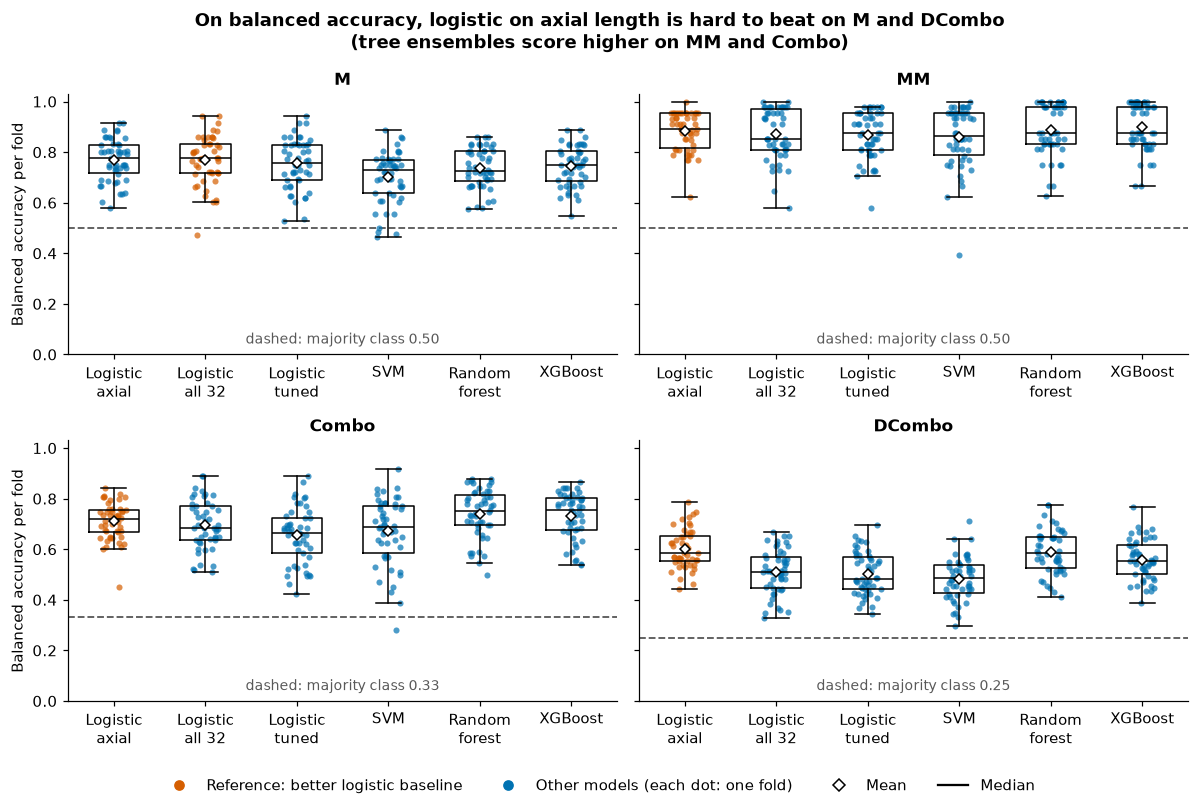

In [3]:
references = {t: scores.loc[t].loc[[n for n in scores.loc[t].index if n.startswith("Logistic,") and n != "Logistic, tuned"],
                                  "balanced_accuracy"].idxmax() for t in TARGETS}
names = list(scores.loc["M"].index)
short = {"Logistic, axial length only": "Logistic\naxial", "Logistic, all 32 features": "Logistic\nall 32",
         "Logistic, tuned": "Logistic\ntuned", "SVM (RBF)": "SVM", "Random forest": "Random\nforest", "XGBoost": "XGBoost"}
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for ax, target in zip(axes.ravel(), TARGETS):
    for x, name in enumerate(names):
        values = frames[target, name]["balanced_accuracy"]
        color = VERMILLION if name == references[target] else BLUE
        ax.scatter(x + rng.uniform(-0.15, 0.15, len(values)), values, s=16, color=color, alpha=0.7, linewidths=0)
        ax.boxplot(values, positions=[x], widths=0.55, showfliers=False, medianprops={"color": "black"}, showmeans=True,
                   meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5})
    chance = 1 / Y_train[target].nunique()
    ax.axhline(chance, color="0.35", ls="--", lw=1.2, zorder=0)
    ax.text(2.5, 0.03, f"dashed: majority class {chance:.2f}", ha="center", va="bottom", fontsize=9, color="0.35")
    ax.set_xticks(range(len(names)), [short[n] for n in names])
    ax.set_ylim(0, 1.03)
    ax.set_title(target)
for ax in axes[:, 0]:
    ax.set_ylabel("Balanced accuracy per fold")
fig.suptitle('On balanced accuracy, logistic on axial length is hard to beat on M and DCombo\n(tree ensembles score higher on MM and Combo)', fontweight="bold")
fig.tight_layout()
fig.legend(handles=[
    Line2D([], [], marker="o", ls="", color=VERMILLION, label="Reference: better logistic baseline"),
    Line2D([], [], marker="o", ls="", color=BLUE, label="Other models (each dot: one fold)"),
    Line2D([], [], marker="D", ls="", markerfacecolor="white", markeredgecolor="black", label="Mean"),
    Line2D([], [], color="black", label="Median"),
], loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4)
save_fig(fig, "04_model_comparison")
plt.show()

**Findings.** On `M`, `Combo` and `DCombo`, logistic regression on axial length alone is at or near the top on balanced accuracy; only the random forest and XGBoost on `Combo` are clearly higher. `MM` is different: the two tree ensembles score highest (0.89 and 0.90 against 0.88), with clearly higher macro-F1 and accuracy (0.96 against 0.88). Tuning the logistic regression does not help on any target. The spread between folds is wide, so only the paired comparison below can tell small gaps apart.

## 5. Does any candidate pass the test?

**What and why:** each candidate is compared with the reference of its target, repeat by repeat. Only candidates that pass can win.

In [4]:
rows = {(t, name): selection_test(frames[t, name], frames[t, references[t]])
        for t in TARGETS for name in names if name != references[t]}
tests = pd.DataFrame(rows).T
tests.index.names = ["target", "compared with its reference"]
print("Reference of each target:", references)
display(tests.apply(lambda c: c.astype(float).round(3) if c.name.endswith("difference") else c))

first_round = {}
for target in TARGETS:
    passing = tests.loc[target][tests.loc[target]["passes"]].index
    first_round[target] = scores.loc[target].loc[passing, "balanced_accuracy"].idxmax() if len(passing) else None
print("Passes on the first set of folds:", first_round)
n_tests = len(tests)

Reference of each target: {'M': 'Logistic, all 32 features', 'MM': 'Logistic, axial length only', 'Combo': 'Logistic, axial length only', 'DCombo': 'Logistic, axial length only'}


balanced_accuracy: difference balanced_accuracy: verdict  macro_f1: difference    macro_f1: verdict  accuracy: difference  \
target compared with its reference                                                                                                                              
M      Logistic, axial length only                         -0.002        no clear difference                -0.007  no clear difference                -0.010   
       Logistic, tuned                                     -0.014        no clear difference                -0.015  no clear difference                -0.016   
       SVM (RBF)                                           -0.068              clearly worse                -0.067        clearly worse                -0.051   
       Random forest                                       -0.033              clearly worse                -0.027        clearly worse                -0.019   
       XGBoost                                             -0.025        no clear difference                -0.025  no clear difference                -0.025   
MM     Logistic, all 32 features                           -0.010        no clear difference                 0.032       clearly better                 0.032   
       Logistic, tuned                                     -0.016        no clear difference                 0.012  no clear difference                 0.015   
       SVM (RBF)                                           -0.024        no clear difference                 0.016  no clear difference                 0.021   
       Random forest                                        0.007        no clear difference                 0.097       clearly better                 0.076   
       XGBoost                                              0.019             clearly better                 0.104       clearly better                 0.077   
Combo  Logistic, all 32 features                           -0.014        no clear difference                 0.009  no clear difference                 0.020   
       Logistic, tuned                                     -0.054              clearly worse                -0.040        clearly worse                -0.031   
       SVM (RBF)                                           -0.040              clearly worse                -0.001  no clear difference                 0.001   
       Random forest                                        0.031             clearly better                 0.084       clearly better                 0.073   
       XGBoost                                              0.022             clearly better                 0.076       clearly better                 0.063   
DCombo Logistic, all 32 features                           -0.090              clearly worse                -0.078        clearly worse                -0.069   
       Logistic, tuned                                     -0.097              clearly worse                -0.090        clearly worse                -0.077   
       SVM (RBF)                                           -0.117              clearly worse                -0.101        clearly worse                -0.094   
       Random forest                                       -0.010        no clear difference                 0.009  no clear difference                -0.000   
       XGBoost                                             -0.044              clearly worse                -0.026  no clear difference                -0.035   

                                      accuracy: verdict passes route  
target compared with its reference                                    
M      Logistic, axial length only  no clear difference  False        
       Logistic, tuned              no clear difference  False        
       SVM (RBF)                          clearly worse  False        
       Random forest                no clear difference  False        
       XGBoost                      no clear difference  False     

Passes on the first set of folds: {'M': None, 'MM': 'XGBoost', 'Combo': 'Random forest', 'DCombo': None}


A result on one set of folds can be luck, so each candidate that came first is run again on new folds, with the reference, and must pass again.

In [5]:
# The catalog also lists the ratio and ordinal options, which section 6 explains.
X_ratio = with_axial_corneal_ratio(X_train)
FEATURES = list(X_train.columns)
catalog = {"Logistic, axial length only": (logistic_baseline, ["axial_length"]),
           "Logistic, all 32 features": (logistic_baseline, FEATURES),
           **{n: (lambda n=n: tuned_model(n), FEATURES) for n in CANDIDATES},
           "Logistic, ratio only": (logistic_baseline, ["axial_corneal_ratio"]),
           "Logistic, axial + ratio": (logistic_baseline, ["axial_length", "axial_corneal_ratio"]),
           "Logistic, all 32 + ratio": (logistic_baseline, FEATURES + ["axial_corneal_ratio"]),
           "Random forest + ratio": (lambda: tuned_model("Random forest"), FEATURES + ["axial_corneal_ratio"]),
           "Ordinal, axial": (ordinal_model, ["axial_length"]),
           "Ordinal, axial + ratio": (ordinal_model, ["axial_length", "axial_corneal_ratio"])}

def run_model(target, name, seed=RANDOM_STATE):
    factory, columns = catalog[name]
    return evaluate(factory(), X_ratio[columns], Y_train[target], Y_train[target], strata[target], seed=seed)

winners, second_round = {}, {}
for target in TARGETS:
    winners[target] = references[target]
    if first_round[target]:
        new, _ = run_model(target, first_round[target], SECOND_SEED)
        reference, _ = run_model(target, references[target], SECOND_SEED)
        second_round[target] = selection_test(new, reference)
        if second_round[target]["passes"]:
            winners[target] = first_round[target]
if second_round:
    display(pd.DataFrame(second_round).T)
final = pd.DataFrame({t: scores.loc[(t, winners[t])] for t in TARGETS}).T.astype(float).round(2)
final.insert(0, "chosen model", [winners[t] for t in TARGETS])
final

,balanced_accuracy: difference,balanced_accuracy: verdict,macro_f1: difference,macro_f1: verdict,accuracy: difference,accuracy: verdict,passes,route
MM,0.012586,no clear difference,0.09582,clearly better,0.073675,clearly better,True,B
Combo,0.012884,no clear difference,0.061399,clearly better,0.055556,clearly better,True,B


,chosen model,balanced_accuracy,balanced_accuracy_sd,macro_f1,accuracy,mcc
M,"Logistic, all 32 features",0.77,0.10,0.76,0.78,0.53
MM,XGBoost,0.90,0.09,0.90,0.96,0.82
Combo,Random forest,0.74,0.10,0.74,0.72,0.54
DCombo,"Logistic, axial length only",0.60,0.08,0.58,0.56,0.41


**Findings.** Nothing passes on `M` or `DCombo`, so their references stay: logistic regression on all 32 features for `M` and on axial length for `DCombo`. On `MM`, XGBoost passes by route A, and again by route B on the second set of folds. On `Combo`, the random forest and XGBoost both pass by route A, with the forest slightly ahead; it passes again by route B on the second set of folds. *These choices are the reference for the experiments in section 6.*

## 6. Can medical knowledge or the order of the classes improve on this?

**What and why:** these two experiments were written down before being run (B15). They come from two limits seen above. The simple references use only the length of the eye, although the eye focuses through its length and its cornea together. And `C`, `M1`, `M2` and `MM` have a natural order that the models so far ignore.

**The axial/corneal ratio.** A person becomes myopic when the eye is too long for the power of the cornea, so the ratio of axial length to corneal radius combines both. The literature describes it as a marker of refractive state:

- Yebra-Pimentel et al. (2004), in 193 university students with a mean age of 22, report a mean ratio that rises with myopia: 3.01 in low, 3.10 in moderate and 3.23 in high myopia, against 2.98 in emmetropes. It is the closest population to ours.
- Fan, Huang and Huang (2024), in 187 adult patients who were all myopic, report that the ratio is more strongly related to refractive error than axial length alone. Their introduction notes, citing earlier work, that a value of 3 is described in children and adolescents as the point where the cornea can no longer compensate. Because all their patients are myopic, this does not directly address telling myopic from non-myopic students.

The brief does not state the units of the keratometry columns. We deduced that they are in dioptres, from the checks printed below (B16). They are converted with the standard formula, radius = 337.5 / dioptres, using the mean of the four values, which notebook 02 showed to be near duplicates. The ratio is computed row by row without labels, so it leaks nothing. We use the published ratio as an idea to test here, not as a fixed cut-off.

**The ordinal model.** A proportional-odds logistic regression, also not covered in class, learns one severity score and cuts it into ordered classes. If `M` and `Combo` are derived from it, those targets cannot contradict `DCombo`. Class weights are balanced to match the other candidates.

**References**
- Yebra-Pimentel E, Giráldez MJ, Glez.-Méijome JM, Cerviño A, García-Resúa C, Parafita MA. Variation of the axial length/corneal radius ratio with ocular refractive status (title translated from Spanish). *Archivos de la Sociedad Española de Oftalmología* 2004;79(7):317-324. [Record](https://investigacion.usc.gal/documentos/5d1df6ec29995204f767c908?lang=en)
- Fan, Huang, Huang. Association between Axial Length to Corneal Curvature Radius Ratio and Myopia in Adult Patients. *Journal of Ophthalmology*, 2024. [PMC10917480](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC10917480/)
- Keratometry, SPIE Optipedia. [Link](https://lux.spie.org/publications/spie-publication-resources/optipedia-free-optics-information/fg04_p42_keratometry)

First, the deduction about the units. Values near 40 cannot be a radius in millimetres, which is close to 8. If they are dioptres, the converted radius should be a typical human value, the two readings of each eye should differ by a normal astigmatism, and longer eyes should tend to have flatter corneas.

In [6]:
readings = X_train[["kerato_od", "kerato_od_axis2", "kerato_os", "kerato_os_axis2"]]
mean_k = readings.mean(axis=1)
print(f"keratometry range: {readings.min().min():.1f} to {readings.max().max():.1f}")
print(f"radius if dioptres: mean {(337.5 / mean_k).mean():.2f} mm, range {(337.5 / mean_k).min():.2f} to {(337.5 / mean_k).max():.2f} mm")
for eye in ["od", "os"]:
    gap = readings[f"kerato_{eye}_axis2"] - readings[f"kerato_{eye}"]
    print(f"{eye}: second reading >= first in {(gap >= 0).mean():.0%} of students, mean difference {gap.mean():.2f}")
print(f"correlation of mean keratometry with axial length: {mean_k.corr(X_train['axial_length']):.2f}")

keratometry range: 36.5 to 48.4
radius if dioptres: mean 7.80 mm, range 7.13 to 9.07 mm
od: second reading >= first in 100% of students, mean difference 0.98
os: second reading >= first in 100% of students, mean difference 1.00
correlation of mean keratometry with axial length: -0.46


**Findings.** All four checks fit dioptres, so we work with that deduction. It remains a deduction, because no document confirms the units. Does the ratio then behave in our data as the literature describes? The figure uses all training students.

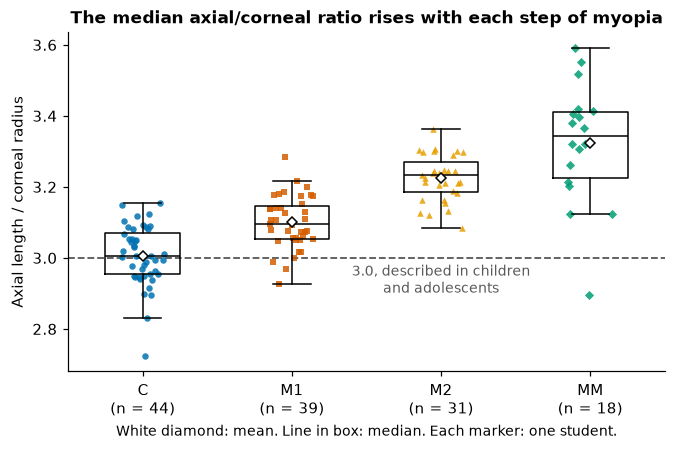

,count,mean
DCombo,,
C,44,3.01
M1,39,3.10
M2,31,3.23
MM,18,3.32


In [7]:
RATIO = "axial_corneal_ratio"
fig, ax = plt.subplots(figsize=(7, 4))
order = ["C", "M1", "M2", "MM"]
for x, cls in enumerate(order):
    values = X_ratio.loc[Y_train["DCombo"] == cls, RATIO]
    ax.scatter(x + rng.uniform(-0.15, 0.15, len(values)), values, s=18, alpha=0.85, linewidths=0,
               color=CLASS_COLORS["DCombo"][cls], marker=CLASS_MARKERS[cls])
    ax.boxplot(values, positions=[x], widths=0.5, showfliers=False, medianprops={"color": "black"}, showmeans=True,
               meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5})
ax.axhline(3, color="0.35", ls="--", lw=1.2, zorder=0)
ax.text(2, 2.985, "3.0, described in children\nand adolescents", ha="center", va="top", fontsize=9, color="0.35")
counts = Y_train["DCombo"].value_counts()
ax.set_xticks(range(4), [f"{c}\n(n = {counts[c]})" for c in order])
ax.set_ylabel("Axial length / corneal radius")
ax.set_xlabel("White diamond: mean. Line in box: median. Each marker: one student.", fontsize=9)
ax.set_title("The median axial/corneal ratio rises with each step of myopia")
save_fig(fig, "04_ratio_by_class")
plt.show()
X_ratio.groupby(Y_train["DCombo"])[RATIO].agg(["count", "mean"]).reindex(order).round(2)

Now each option runs on the folds of its target and is compared with the model chosen in section 5, with the same test. Options derived from the ordinal model use the folds of `DCombo`, so they are compared per repeat and not on the same folds.

In [8]:
def repeat_scores(predicted, truth):
    rows = []
    for repeat in range(N_REPEATS):
        p = predicted[:, repeat]
        rows.append({"repeat": repeat, "balanced_accuracy": balanced_accuracy_score(truth, p),
                     "macro_f1": f1_score(truth, p, average="macro"), "accuracy": accuracy_score(truth, p)})
    return pd.DataFrame(rows)

def derive(dcombo, target):
    return np.where(dcombo == "C", "NO", "SI") if target == "M" else np.where(np.isin(dcombo, ["M1", "M2"]), "M", dcombo)

options = {"M": ["Logistic, ratio only", "Logistic, axial + ratio"],
           "MM": ["Logistic, ratio only", "Logistic, axial + ratio", "Logistic, all 32 + ratio"],
           "Combo": ["Logistic, ratio only", "Logistic, axial + ratio", "Random forest + ratio"],
           "DCombo": ["Logistic, ratio only", "Logistic, axial + ratio", "Ordinal, axial", "Ordinal, axial + ratio"]}
ORDINALS = ["Ordinal, axial", "Ordinal, axial + ratio"]

def score_option(target, name, seed):
    """Fold scores and predictions of an option; derived targets are scored per repeat."""
    if name.startswith("Derived from "):
        _, dcombo = run_model("DCombo", name.removeprefix("Derived from "), seed)
        predicted = derive(dcombo, target)
        return repeat_scores(predicted, Y_train[target]), predicted
    return run_model(target, name, seed)

def reference_for(target, name, frame, pred):
    return repeat_scores(pred, Y_train[target]) if name.startswith("Derived from ") else frame

rows, option_frames, option_predictions = {}, {}, {}
for target in TARGETS:
    names = options[target] + ([f"Derived from {o}" for o in ORDINALS] if target in ("M", "Combo") else [])
    for name in names:
        frame, pred = score_option(target, name, RANDOM_STATE)
        option_frames[target, name], option_predictions[target, name] = frame, pred
        rows[target, name] = {"mean balanced accuracy": frame["balanced_accuracy"].mean(),
                              **selection_test(frame, reference_for(target, name, frames[target, winners[target]], predictions[target, winners[target]]))}
option_tests = pd.DataFrame(rows).T
display(option_tests.apply(lambda c: c.astype(float).round(3) if c.name.endswith("difference") or c.name.startswith("mean") else c))
n_tests += len(option_tests)

mean balanced accuracy  balanced_accuracy: difference balanced_accuracy: verdict  macro_f1: difference  \
M      Logistic, ratio only                                  0.795                          0.026        no clear difference                 0.015   
       Logistic, axial + ratio                               0.805                          0.035             clearly better                 0.025   
       Derived from Ordinal, axial                           0.739                         -0.031              clearly worse                -0.016   
       Derived from Ordinal, axial + ratio                   0.758                         -0.012        no clear difference                 0.003   
MM     Logistic, ratio only                                  0.780                         -0.121              clearly worse                -0.219   
       Logistic, axial + ratio                               0.897                         -0.005        no clear difference                -0.098   
       Logistic, all 32 + ratio                              0.885                         -0.016        no clear difference                -0.058   
Combo  Logistic, ratio only                                  0.673                         -0.069              clearly worse                -0.120   
       Logistic, axial + ratio                               0.736                         -0.005        no clear difference                -0.052   
       Random forest + ratio                                 0.771                          0.030             clearly better                 0.030   
       Derived from Ordinal, axial                           0.752                          0.010        no clear difference                 0.009   
       Derived from Ordinal, axial + ratio                   0.740                         -0.002        no clear difference                 0.001   
DCombo Logistic, ratio only                                  0.611                          0.010        no clear difference                 0.021   
       Logistic, axial + ratio                               0.653                          0.051             clearly better                 0.062   
       Ordinal, axial                                        0.635                          0.034             clearly better                 0.052   
       Ordinal, axial + ratio                                0.623                          0.022             clearly better                 0.042   

                                              macro_f1: verdict  accuracy: difference    accuracy: verdict passes route  
M      Logistic, ratio only                 no clear difference                 0.006  no clear difference  False        
       Logistic, axial + ratio              no clear difference                 0.016  no clear difference   True     A  
       Derived from Ordinal, axial          no clear difference                -0.002  no clear difference  False        
       Derived from Ordinal, axial + ratio  no clear difference                 0.014  no clear difference  False        
MM     Logistic, ratio only                       clearly worse                -0.162        clearly worse  False        
       Logistic, axial + ratio                    clearly worse                -0.074        clearly worse  False        
       Logistic, all 32 + ratio                   clearly worse                -0.038        clearly worse  False        
Combo  Logistic, ratio only                       clearly worse                -0.089        clearly worse  False        
       Logistic, axial + ratio                    clearly worse                -0.031        clearly worse  False        
       Random forest + ratio                     clearly better                 0.035       clearly better   True     A  
       Derived from Ordinal, axial          no clear difference                 0.015  no clear difference  False        
       Derived from Ordinal, 

Balanced accuracy depends on the threshold of 0.5. Two scores that do not depend on it, AUC and average precision, give a second view of the ratio on `MM`. With about 4 positives per fold they are noisy.

In [9]:
mm_views = {"Logistic, axial length only": frames["MM", "Logistic, axial length only"],
            "Logistic, all 32 features": frames["MM", "Logistic, all 32 features"],
            "Logistic, ratio only": option_frames["MM", "Logistic, ratio only"]}
pd.DataFrame({name: frame[["auc", "average_precision"]].mean() for name, frame in mm_views.items()}).T.round(3)

,auc,average_precision
"Logistic, axial length only",0.984,0.945
"Logistic, all 32 features",0.961,0.852
"Logistic, ratio only",0.871,0.780


As before, the option with the highest balanced accuracy among those that pass runs again on new folds, and must pass again.

In [10]:
chosen_before = dict(winners)
second = {}
for target in TARGETS:
    passing = option_tests.loc[target][option_tests.loc[target]["passes"].astype(bool)]
    if passing.empty:
        continue
    pick = passing["mean balanced accuracy"].astype(float).idxmax()
    new, new_pred = score_option(target, pick, SECOND_SEED)
    old, old_pred = run_model(target, chosen_before[target], SECOND_SEED)
    second[target, pick] = selection_test(new, reference_for(target, pick, old, old_pred))
    if second[target, pick]["passes"]:
        winners[target] = pick
        frames[target, pick], predictions[target, pick] = option_frames[target, pick], option_predictions[target, pick]
display(pd.DataFrame(second).T)
columns = ["balanced_accuracy", "macro_f1", "accuracy", "recall_SI", "recall_NO"]
final = pd.DataFrame({t: frames[t, winners[t]].reindex(columns=columns).mean() for t in TARGETS}).T.round(2)
final.insert(0, "chosen model", [winners[t] for t in TARGETS])
final.insert(1, "chosen before this section", [chosen_before[t] for t in TARGETS])
final

,,balanced_accuracy: difference,balanced_accuracy: verdict,macro_f1: difference,macro_f1: verdict,accuracy: difference,accuracy: verdict,passes,route
M,"Logistic, axial + ratio",0.038693,clearly better,0.028776,no clear difference,0.02265,no clear difference,True,A
Combo,Random forest + ratio,0.03254,clearly better,0.033929,clearly better,0.038405,clearly better,True,A
DCombo,"Logistic, axial + ratio",0.048294,clearly better,0.055687,clearly better,0.065954,clearly better,True,A


,chosen model,chosen before this section,balanced_accuracy,macro_f1,accuracy,recall_SI,recall_NO
M,"Logistic, axial + ratio","Logistic, all 32 features",0.80,0.78,0.80,0.78,0.83
MM,XGBoost,XGBoost,0.90,0.90,0.96,0.82,0.98
Combo,Random forest + ratio,Random forest,0.77,0.77,0.76,NaN,NaN
DCombo,"Logistic, axial + ratio","Logistic, axial length only",0.65,0.64,0.63,NaN,NaN


**Findings.** The ratio rises at every step of myopia in our students, as in the literature, with overlap between groups. It passes the test on three targets, again on new folds: `M` and `DCombo` now use logistic regression on axial length plus the ratio, and `Combo` the random forest with the ratio added. It does not help `MM`: every option with the ratio is clearly worse than XGBoost on macro-F1 and accuracy, and the ratio alone separates `MM` less well than axial length (AUC 0.87 against 0.98), so `MM` keeps XGBoost. The ordinal model passes on `DCombo`, but logistic regression with the ratio scores higher. The ratio was not added to XGBoost or the SVM. Section 11 shows the gains are smaller than this table suggests.

## 7. Do the chosen models need the ancestry flag? (B17)

**What and why:** `foreign_ancestors` reads an empty ancestry entry, about three quarters of the students, as "no foreign ancestors". If a chosen model uses it, three variants run on the same folds: keep it as it is (the reference here), drop it, or add a flag for an empty entry. A variant is adopted only if it passes the same test. Phototype is no longer a feature (B9, notebook 02).

In [11]:
ancestry_missing = X_train_raw["origen antepasados (extranjeros)"].isna().astype(float)
rows = {}
for target in TARGETS:
    factory, columns = catalog[winners[target]]
    if "foreign_ancestors" not in columns:
        continue
    data = X_ratio[columns]
    variants = {"Drop foreign_ancestors": data.drop(columns="foreign_ancestors"),
                "Add missing flag": data.assign(ancestry_missing=ancestry_missing)}
    for label, variant in variants.items():
        frame, _ = evaluate(factory(), variant, Y_train[target], Y_train[target], strata[target])
        rows[target, label] = selection_test(frame, frames[target, winners[target]])
n_tests += len(rows)
if rows:
    display(pd.DataFrame(rows).T)
else:
    print("No chosen model uses foreign_ancestors.")

balanced_accuracy: difference balanced_accuracy: verdict macro_f1: difference    macro_f1: verdict accuracy: difference  \
MM    Drop foreign_ancestors                     -0.007915        no clear difference            -0.006635  no clear difference            -0.003048   
      Add missing flag                           -0.002045        no clear difference            -0.000623  no clear difference            -0.000028   
Combo Drop foreign_ancestors                     -0.003505        no clear difference            -0.002222  no clear difference            -0.003818   
      Add missing flag                            0.001693        no clear difference             0.001847  no clear difference             0.001425   

                                accuracy: verdict passes route  
MM    Drop foreign_ancestors  no clear difference  False        
      Add missing flag        no clear difference  False        
Combo Drop foreign_ancestors  no clear difference  False        
      Add missing flag        no clear difference  False

**Findings.** Only the `Combo` random forest uses `foreign_ancestors`, and no variant passes there: dropping it or flagging empty entries moves balanced accuracy by less than 0.01. *Decision (B17): the flag stays as it is, with an empty entry read as "no foreign ancestors".*

## 8. Can a tuned threshold improve `MM`?

**What and why:** the model says `SI` when the estimated probability passes 0.5, which is only a default. With 18 positives, another threshold could find more of them at the cost of more false alarms. The threshold is chosen inside the training rows of each outer fold, once for balanced accuracy and once for macro-F1, and must pass the same test against the same model at 0.5.

In [12]:
factory, columns = catalog[winners["MM"]]
mm_default = frames["MM", winners["MM"]]
shown = SUMMARY_METRICS + ["recall_SI", "recall_NO"]
rows, means = {}, {"Threshold 0.5": mm_default[shown].mean()}
for scoring in ["balanced_accuracy", "f1_macro"]:
    frame, _ = evaluate(with_tuned_threshold(factory(), scoring=scoring), X_ratio[columns], Y_train["MM"], Y_train["MM"], strata["MM"])
    rows[f"Tuned on {scoring}"] = selection_test(frame, mm_default)
    means[f"Tuned on {scoring}"] = frame[shown].mean()
display(pd.DataFrame(means).T.round(3))
display(pd.DataFrame(rows).T)
n_tests += len(rows)
print(f"Accuracy of always saying the majority class on MM: {Y_train['MM'].value_counts(normalize=True).max():.3f}")

passing = [k for k, v in rows.items() if v["passes"]]
threshold_scoring, mm_before = None, predictions["MM", winners["MM"]]
final_frames = {t: frames[t, winners[t]] for t in TARGETS}
if passing:
    pick = max(passing, key=lambda k: means[k]["balanced_accuracy"])
    scoring = pick.removeprefix("Tuned on ")
    new, _ = evaluate(with_tuned_threshold(factory(), scoring=scoring), X_ratio[columns], Y_train["MM"], Y_train["MM"], strata["MM"], seed=SECOND_SEED)
    old, _ = run_model("MM", winners["MM"], SECOND_SEED)
    check = selection_test(new, old)
    print(pick, "on the second set of folds:", {k: check[k] for k in ["balanced_accuracy: verdict", "macro_f1: verdict", "accuracy: verdict", "passes", "route"]})
    if check["passes"]:
        threshold_scoring = scoring
        final_frames["MM"], predictions["MM", winners["MM"]] = evaluate(with_tuned_threshold(factory(), scoring=scoring), X_ratio[columns], Y_train["MM"], Y_train["MM"], strata["MM"])
print("Threshold tuned on:", threshold_scoring)
final_frames["MM"] = final_frames["MM"] if threshold_scoring else mm_default
against = {f"Against {name}": selection_test(final_frames["MM"], frames["MM", name]) for name in [references["MM"], chosen_before["MM"]]}
display(pd.DataFrame(against).T)

,balanced_accuracy,macro_f1,accuracy,mcc,recall_SI,recall_NO
Threshold 0.5,0.901,0.903,0.957,0.820,0.825,0.977
Tuned on balanced_accuracy,0.895,0.870,0.932,0.764,0.845,0.945
Tuned on f1_macro,0.898,0.899,0.955,0.813,0.820,0.975


,balanced_accuracy: difference,balanced_accuracy: verdict,macro_f1: difference,macro_f1: verdict,accuracy: difference,accuracy: verdict,passes,route
Tuned on balanced_accuracy,-0.006285,no clear difference,-0.033519,clearly worse,-0.0249,clearly worse,False,
Tuned on f1_macro,-0.003389,no clear difference,-0.004021,no clear difference,-0.002279,no clear difference,False,


Accuracy of always saying the majority class on MM: 0.864
Threshold tuned on: None


,balanced_accuracy: difference,balanced_accuracy: verdict,macro_f1: difference,macro_f1: verdict,accuracy: difference,accuracy: verdict,passes,route
"Against Logistic, axial length only",0.018613,clearly better,0.104305,clearly better,0.077436,clearly better,True,A
Against XGBoost,0.0,no clear difference,0.0,no clear difference,0.0,no clear difference,False,


The threshold step was tried only on the model that won at 0.5, so the next table shows whether the order mattered: each `MM` option at 0.5 and with each tuned threshold.

In [13]:
names = ["Logistic, ratio only", "Logistic, axial + ratio", "Logistic, all 32 + ratio", "Logistic, all 32 features", "Logistic, axial length only"]
shown = ["balanced_accuracy", "macro_f1", "accuracy", "recall_SI"]
table = {}
for name in names:
    factory, columns = catalog[name]
    table[name, "at 0.5"] = run_model("MM", name)[0][shown].mean()
    for scoring, label in [("balanced_accuracy", "balanced accuracy"), ("f1_macro", "macro-F1")]:
        table[name, f"tuned on {label}"] = evaluate(with_tuned_threshold(factory(), scoring=scoring), X_ratio[columns], Y_train["MM"], Y_train["MM"], strata["MM"])[0][shown].mean()
pd.DataFrame(table).T.round(3)

balanced_accuracy  macro_f1  accuracy  recall_SI
Logistic, ratio only        at 0.5                                  0.780     0.684     0.795      0.760
                            tuned on balanced accuracy              0.776     0.736     0.852      0.670
                            tuned on macro-F1                       0.776     0.790     0.911      0.590
Logistic, axial + ratio     at 0.5                                  0.897     0.806     0.883      0.917
                            tuned on balanced accuracy              0.874     0.789     0.870      0.880
                            tuned on macro-F1                       0.866     0.871     0.942      0.762
Logistic, all 32 + ratio    at 0.5                                  0.885     0.845     0.919      0.840
                            tuned on balanced accuracy              0.885     0.794     0.875      0.900
                            tuned on macro-F1                       0.867     0.845     0.925      0.787
Logistic, all 32 features   at 0.5                                  0.873     0.831     0.911      0.820
                            tuned on balanced accuracy              0.874     0.769     0.851      0.905
                            tuned on macro-F1                       0.856     0.828     0.916      0.775
Logistic, axial length only at 0.5                                  0.882     0.799     0.879      0.887
                            tuned on balanced accuracy              0.878     0.830     0.903      0.845
                            tuned on macro-F1                       0.905     0.910     0.961      0.830

If a tuned threshold is adopted, the next cell checks how much it moves with the inner split, since the test labels come from a single fit on all students.

In [14]:
factory, columns = catalog[winners["MM"]]
thresholds, predicted_positive = [], []
for seed in range(10 if threshold_scoring else 0):
    cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=10, random_state=seed)
    model = TunedThresholdClassifierCV(factory(), scoring=threshold_scoring or "balanced_accuracy", cv=cv, random_state=RANDOM_STATE).fit(X_ratio[columns], Y_train["MM"])
    thresholds.append(model.best_threshold_)
    predicted_positive.append(int((model.predict(X_ratio[columns]) == "SI").sum()))
if thresholds:
    print(f"threshold over 10 inner seeds: {min(thresholds):.2f} to {max(thresholds):.2f}, median {np.median(thresholds):.2f}")
    print(f"training students predicted SI: {min(predicted_positive)} to {max(predicted_positive)} of {len(X_ratio)}")
else:
    print("No tuned threshold was adopted, so the final MM model says SI above a probability of 0.5.")

No tuned threshold was adopted, so the final MM model says SI above a probability of 0.5.


Notebook 01 showed that the 8 students with `Combo = MM` and `MM = NO` have an axial length like that of the `MM = SI` group. The ratio adds the cornea, so the next table compares the groups again, with how often the `MM` model says `SI` for each one.

In [15]:
keratometry = X_train[["kerato_od", "kerato_od_axis2", "kerato_os", "kerato_os_axis2"]].mean(axis=1)
groups = {"MM = SI as provided": Y_provided["MM"] == "SI", "The 8 corrected (B2)": (Y_provided["MM"] == "NO") & (Y_provided["Combo"] == "MM"),
          "Combo = M": Y_train["Combo"] == "M", "Combo = C": Y_train["Combo"] == "C"}
final_mm = predictions["MM", winners["MM"]]
is_mm = Y_train["Combo"] == "MM"
myopic = Y_train["Combo"].isin(["M", "MM"])
print(f"Telling Combo = MM from Combo = M, AUC: axial length {roc_auc_score(is_mm[myopic], X_train.loc[myopic, 'axial_length']):.3f}, ratio {roc_auc_score(is_mm[myopic], X_ratio.loc[myopic, RATIO]):.3f}")
inconsistent = groups["The 8 corrected (B2)"]
print(f"Ratio of the 8: {X_ratio.loc[inconsistent, RATIO].min():.2f} to {X_ratio.loc[inconsistent, RATIO].max():.2f}; of MM = SI as provided: {X_ratio.loc[groups['MM = SI as provided'], RATIO].min():.2f} to {X_ratio.loc[groups['MM = SI as provided'], RATIO].max():.2f}")
pd.DataFrame({g: {"students": int(m.sum()), "axial length (mm)": X_train.loc[m, "axial_length"].mean(),
                  "keratometry (D)": keratometry[m].mean(), "ratio": X_ratio.loc[m, RATIO].mean(),
                  "says SI at 0.5": (mm_before[m.values] == "SI").mean(), "says SI, final model": (final_mm[m.values] == "SI").mean()}
              for g, m in groups.items()}).T.round(2)

Telling Combo = MM from Combo = M, AUC: axial length 0.968, ratio 0.827
Ratio of the 8: 3.12 to 3.40; of MM = SI as provided: 2.90 to 3.59


,students,axial length (mm),keratometry (D),ratio,says SI at 0.5,"says SI, final model"
MM = SI as provided,10.0,26.35,43.40,3.39,0.71,0.71
The 8 corrected (B2),8.0,26.52,41.28,3.24,0.98,0.98
Combo = M,70.0,24.47,43.55,3.16,0.04,0.04
Combo = C,44.0,23.47,43.27,3.01,0.00,0.00


**Findings.** Neither tuned threshold passes. Tuning on balanced accuracy finds slightly more positives (recall of `SI` 0.85 against 0.82) but is clearly worse on macro-F1 and accuracy; tuning on macro-F1 makes no clear difference. *Decision: `MM` uses XGBoost at the default threshold of 0.5.* It finds about four positives in five, with very few false alarms (recall of `NO` 0.98), and its accuracy of 0.96 is clearly above the 0.86 of the majority class. The table also shows that logistic regression on axial length with a threshold tuned on macro-F1 scores about the same; it was not chosen because the protocol tunes the threshold only on the winner.

The group table adds something to the label question. The 8 corrected students have eyes as long as those with `MM = SI` but flatter corneas, so their mean ratio is lower. One possible explanation is that the cornea partly compensates their long eyes, keeping their refraction under the 6 dioptres that define `MM`. If so, the labels as provided would be right, which weighs against B2. It is a hypothesis about 8 students: the data hold no refraction values. How often the final model says `SI` for them is not evidence either way, because it was trained with them labelled `SI`.

## 9. Separate models, or one model for everything? (B3)

**What and why:** the four targets are related, so `M` and `Combo` could be derived from the chosen `DCombo` model instead of having their own (`C` means no myopia, and `M1` and `M2` together are `M`). `MM` cannot be derived, because the labels of `MM` and `DCombo` differ for 8 students. Separate models stay unless the derived ones pass the test. Scores here are computed per repeat from the out-of-fold predictions, on the folds of each model.

In [16]:
dcombo = predictions["DCombo", winners["DCombo"]]
rows, means = {}, {}
for target in ("M", "Combo"):
    own = repeat_scores(predictions[target, winners[target]], Y_train[target])
    from_dcombo = repeat_scores(derive(dcombo, target), Y_train[target])
    rows[target] = selection_test(from_dcombo, own)
    n_tests += 1
    means[target, "own model"] = own.drop(columns="repeat").mean()
    means[target, "derived from DCombo"] = from_dcombo.drop(columns="repeat").mean()
display(pd.DataFrame(means).T.round(3))
pd.DataFrame(rows).T

balanced_accuracy  macro_f1  accuracy
M     own model                        0.805     0.785     0.798
      derived from DCombo              0.791     0.790     0.813
Combo own model                        0.771     0.776     0.759
      derived from DCombo              0.759     0.745     0.748

,balanced_accuracy: difference,balanced_accuracy: verdict,macro_f1: difference,macro_f1: verdict,accuracy: difference,accuracy: verdict,passes,route
M,-0.014205,clearly worse,0.005432,no clear difference,0.015152,clearly better,False,
Combo,-0.012145,no clear difference,-0.030255,clearly worse,-0.011364,no clear difference,False,


Separate models can contradict each other, so the next table counts how often the chosen models do so for the same student, as a share of all out-of-fold predictions. The last row is shown only for information: that combination existed in the provided labels of 8 students, which B2 corrects, and no prediction is forced to agree (B3).

In [17]:
m, mm, combo, dc = (predictions[t, winners[t]] for t in TARGETS)
contradictions = {
    "M = NO but Combo is not C": (m == "NO") & (combo != "C"),
    "M = SI but Combo = C": (m == "SI") & (combo == "C"),
    "MM = SI but Combo is not MM": (mm == "SI") & (combo != "MM"),
    "MM = SI but M = NO": (mm == "SI") & (m == "NO"),
    "Combo and DCombo disagree on C": (combo == "C") != (dc == "C"),
    "Combo and DCombo disagree on MM": (combo == "MM") != (dc == "MM"),
    "For information: Combo = MM and MM = NO": (combo == "MM") & (mm == "NO"),
}
print(f"In the provided training labels, Combo = MM and MM = NO: {((Y_provided['Combo'] == 'MM') & (Y_provided['MM'] == 'NO')).mean():.2f} of students; after B2: {((Y_train['Combo'] == 'MM') & (Y_train['MM'] == 'NO')).mean():.2f}")
pd.Series({k: v.mean() for k, v in contradictions.items()}, name="share of predictions").round(2).to_frame()

In the provided training labels, Combo = MM and MM = NO: 0.06 of students; after B2: 0.00


,share of predictions
M = NO but Combo is not C,0.07
M = SI but Combo = C,0.01
MM = SI but Combo is not MM,0.01
MM = SI but M = NO,0.01
Combo and DCombo disagree on C,0.07
Combo and DCombo disagree on MM,0.05
For information: Combo = MM and MM = NO,0.00


**Findings.** Deriving from `DCombo` does not pass on `M`, where balanced accuracy is clearly worse, or on `Combo`, where balanced accuracy shows no clear difference and macro-F1 is clearly worse. *Decision (B3): each target keeps its own model.* The price is that the models sometimes contradict each other for the same student. No prediction is changed to force agreement, and the final labels in notebook 05 are checked for these contradictions and the count is reported.

## 10. How do the final models score?

**What and why:** these are the scores to quote for each final model, including the recall of every class, because the averages hide the weak ones. Each row comes from the first set of folds.

In [18]:
recalls = ["recall_NO", "recall_SI", "recall_C", "recall_M", "recall_M1", "recall_M2", "recall_MM"]
final_table = pd.DataFrame({t: final_frames[t].reindex(columns=["balanced_accuracy", "macro_f1", "accuracy", "mcc"] + recalls).mean() for t in TARGETS}).T.round(2)
final_table.insert(1, "balanced_accuracy_sd", [round(final_frames[t]["balanced_accuracy"].std(), 2) for t in TARGETS])
final_table.insert(4, "majority class accuracy", [round(Y_train[t].value_counts(normalize=True).max(), 2) for t in TARGETS])
final_table.insert(0, "final model", [winners[t] + (f", threshold tuned on {threshold_scoring}" if t == "MM" and threshold_scoring else "") for t in TARGETS])
for t in TARGETS:
    assert final_model(t, FEATURES)[1] == catalog[winners[t]][1], t   # notebook 05 fits these same definitions
mm_final = final_model("MM", FEATURES)[0]
assert (mm_final.scoring if isinstance(mm_final, TunedThresholdClassifierCV) else None) == threshold_scoring
final_table.astype(object).where(final_table.notna(), "")

,final model,balanced_accuracy,balanced_accuracy_sd,macro_f1,accuracy,majority class accuracy,mcc,recall_NO,recall_SI,recall_C,recall_M,recall_M1,recall_M2,recall_MM
M,"Logistic, axial + ratio",0.8,0.08,0.78,0.8,0.67,0.59,0.83,0.78,,,,,
MM,XGBoost,0.9,0.09,0.9,0.96,0.86,0.82,0.98,0.82,,,,,
Combo,Random forest + ratio,0.77,0.09,0.77,0.76,0.53,0.6,,,0.74,0.75,,,0.81
DCombo,"Logistic, axial + ratio",0.65,0.07,0.64,0.63,0.33,0.5,,,0.73,,0.49,0.59,0.81


**Findings.** These are the scores of the final models, before the correction for selection in the next section. `MM` has the highest accuracy, and `DCombo` stays the weakest target, with `M1` and `M2` as its hardest classes. The final models are defined in one place, `final_model` in `src/miopia/models.py`, and the cell above checks that they match this notebook. Notebook 05 fits them on all the training students.

## 11. How much of this is optimism?

**What and why:** the winners were chosen and scored on the same students, after many attempts, so their scores flatter them. Two scripts in `src/miopia/experiments/` measure this; they take too long to run here, so the notebook reads their saved results.

- `nested_protocol.py` repeats a simplified version of the whole selection inside each outer training set (about 106 students) and scores the result on the outer rows. The random forest and XGBoost use fixed settings and are candidates on `MM` and `Combo`, where they won here. SVM, tuned logistic regression and the ancestry variants are left out. Its forest is simpler than the tuned one, so the `Combo` column describes the process, not the chosen model.
- `null_calibration.py` replaces the ratio with useless information, a shuffled cornea or random noise, and counts how often the test still passes.

In [19]:
print(f"Selection tests run in this notebook: {n_tests}")
nested = json.loads((RESULTS / "experiments" / "nested_protocol.json").read_text())
display(pd.DataFrame(nested["means"]).T.loc[TARGETS].assign(**{"sd across repeats": pd.Series(nested["sd_across_repeats"]), "outer folds": pd.Series(nested["outer_folds"])}).T.round(3))
print("Model chosen across outer folds:")
for target in TARGETS:
    print(f"  {target}: {nested['chosen_per_fold'][target]}")
print("MM threshold across outer folds:", nested["threshold_per_fold_MM"])
null = json.loads((RESULTS / "experiments" / "null_calibration.json").read_text())
print(f"Runs per row: {null['runs_per_row']}")
pd.DataFrame(null["comparisons"]).T

Selection tests run in this notebook: 44


,M,MM,Combo,DCombo
whole protocol balanced accuracy,0.791,0.912,0.703,0.594
whole protocol macro-F1,0.769,0.926,0.696,0.585
whole protocol accuracy,0.786,0.966,0.682,0.574
fixed choice balanced accuracy,0.809,0.912,0.758,0.658
fixed choice macro-F1,0.788,0.926,0.765,0.642
fixed choice accuracy,0.805,0.966,0.756,0.637
axial logistic balanced accuracy,0.767,0.887,0.713,0.594
axial logistic macro-F1,0.748,0.805,0.664,0.575
axial logistic accuracy,0.773,0.883,0.654,0.554
sd across repeats,0.016,0.006,0.038,0.020


Model chosen across outer folds:
  M: {'axial+ratio': 14, 'ratio': 5, 'axial': 1}
  MM: {'XGB': 20}
  Combo: {'XGB': 10, 'axial+ratio': 3, 'axial': 2}
  DCombo: {'axial+ratio': 8, 'ordinal+ratio': 7, 'ordinal': 3, 'axial': 2}
MM threshold across outer folds: {'none': 20}
Runs per row: 200


,real gain,real test passes,shuffled cornea: pass rate,shuffled cornea: 95th percentile of gain,random noise: pass rate,random noise: 95th percentile of gain
"M, axial + ratio vs axial",0.037,True,0.03,0.005,0.015,0.008
"DCombo, axial + ratio vs axial",0.051,True,0.07,0.018,0.03,0.013
"Combo, axial + ratio vs axial",0.026,True,0.355,0.024,0.305,0.032
"MM, ratio vs axial",-0.102,False,0.045,0.007,0.0,-0.26
"MM, ratio vs all 32",-0.092,False,0.02,0.016,0.0,-0.25


**Findings.** When the choice is repeated inside the folds, the gain over logistic regression on axial length holds on `M` (balanced accuracy 0.79 against 0.77) and on `MM` (0.91 against 0.89, accuracy 0.97 against 0.88), where XGBoost without a tuned threshold is picked in all 20 outer folds. It disappears on `DCombo` (0.59 both), where the choice varies between folds. On `Combo` the whole process ends below the axial model (0.70 against 0.71), and the chosen forest with the ratio is not picked in any outer fold. The scores of section 10 are an upper range; the whole-process scores are the more sober estimate.

On useless information, the test passes rarely on `M` and `DCombo`, and the real gain of the ratio is well above what a shuffled cornea gives, so the cornea carries a real signal there. On `Combo` it passes about one time in three and the real gain is no larger than chance, so the `Combo` choice is weak evidence. On `MM` the ratio fails the real test, which agrees with section 6.

## 12. Summary

| # | Finding | Decision / action |
|---|---|---|
| 1 | Without the ratio, logistic regression on axial length is hard to beat on `M` and `DCombo`; tree ensembles pass on `MM` (XGBoost) and `Combo` (random forest) | Extra complexity is kept only where it passed |
| 2 | The axial/corneal ratio passes on `M`, `Combo` and `DCombo`, but not on `MM` | `M` and `DCombo`: logistic on axial length plus ratio. `Combo`: random forest with the ratio. `MM`: XGBoost on the 32 features |
| 3 | No tuned threshold passes on `MM` | `MM` keeps the default threshold of 0.5 |
| 4 | The 8 corrected students have long eyes but flatter corneas | A hypothesis that weighs against B2; reported as one |
| 5 | The ordinal model does not beat logistic regression with the ratio on `DCombo` | Not chosen; reported as an attempt |
| 6 | Dropping `foreign_ancestors` or flagging empty entries makes no clear difference | B17 closed: kept as it is |
| 7 | Deriving `M` and `Combo` from `DCombo` does not pass | B3 closed: separate models, contradictions counted, not forced |
| 8 | Repeating the selection keeps the gain on `M` and `MM`, removes it on `DCombo`, and ends below the axial model on `Combo`; the test passes too often on useless information on `Combo` | Section 10 scores are an upper range; section 11 gives the sober one |
| 9 | XGBoost on `MM` and the forest on `Combo` pass only by route B on the second set of folds | Kept and disclosed: with route A alone, both targets would keep the axial reference after section 5 |

Route B and the experiments of section 6 were added after seeing validation results, and this notebook runs the number of selection tests printed in section 11, all on the same 132 students. The test set played no part.

**Next notebook (05):** fit each model on all training students, interpret it, analyse its errors, and produce the test labels.